<a href="https://colab.research.google.com/github/DiegoMartell/Machine-Learning/blob/main/hands-on/Hands_on_5_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Hands-on 5: Máquinas de Vectores de Soporte (SVM)
### Clasificación con Scikit-Learn

> **Objetivo del Tutorial**
> Este notebook es una guía interactiva para implementar el algoritmo de **Máquinas de Vectores de Soporte (SVM)** utilizando Python y Scikit-Learn.
> Exploraremos sus fundamentos teóricos, su modelo matemático y lo contrastaremos con el Perceptrón, siguiendo la metodología del **Pipeline de Machine Learning** paso a paso.

## 1. Fundamentos Teóricos de la Técnica SVM

Las Máquinas de Vectores de Soporte (SVM) son modelos de aprendizaje supervisado con algoritmos de aprendizaje asociados que analizan datos y reconocen patrones, utilizados para clasificación y análisis de regresión.

* **El objetivo principal:** Encontrar el **hiperplano óptimo** que separe las diferentes clases de datos con el mayor margen posible.
* **Vectores de Soporte:** Son los puntos de datos que están más cerca del hiperplano. Son los elementos más críticos del conjunto de datos, ya que si se eliminan, alterarían la posición del hiperplano de división.
* **Margen:** Es la distancia entre el hiperplano y los vectores de soporte más cercanos. La SVM busca maximizar este margen para mejorar la generalización del modelo.

## 2. Modelo Matemático

La SVM busca encontrar un hiperplano definido por el vector de pesos $\mathbf{w}$ y el sesgo $b$ que satisfaga las siguientes condiciones para un conjunto de datos linealmente separable:

$$ \mathbf{w} \cdot \mathbf{x}_i + b \ge 1 \quad \text{si } y_i = 1 $$
$$ \mathbf{w} \cdot \mathbf{x}_i + b \le -1 \quad \text{si } y_i = -1 $$

El objetivo es **minimizar** $\frac{1}{2} \|\mathbf{w}\|^2$ sujeto a la restricción:
$$ y_i (\mathbf{w} \cdot \mathbf{x}_i + b) \ge 1 \quad \text{para todo } i $$

> **El Truco del Kernel:**
> Si los datos no son linealmente separables en el espacio original, la SVM utiliza una función matemática llamada **Kernel** para mapear los datos a un espacio de mayor dimensión donde sí puedan ser separados por un hiperplano lineal.

## 3. Contraste: SVM vs Perceptrón

Aunque ambos son clasificadores lineales (en su forma básica), tienen una diferencia fundamental en cómo eligen la frontera de decisión:

* **Perceptrón:** Encuentra *cualquier* línea que separe las clases. Se detiene tan pronto como clasifica correctamente todos los puntos de entrenamiento. Esto puede llevar a una mala generalización en datos nuevos.
* **SVM:** Encuentra la línea que separa las clases con el **margen máximo**. No se conforma con cualquier línea; busca la más segura, la que está más alejada de los puntos críticos (vectores de soporte) de ambas clases.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Librerías base cargadas.")

Librerías base cargadas.


## 4. Pipeline de Machine Learning

### 4.1 Recolección y Descripción del Dataset
Usaremos un dataset sintético clásico generado con Scikit-Learn: `make_blobs`. Esto nos permite crear nubes de puntos controladas para ilustrar el concepto del margen máximo.

In [ ]:
# Importamos la función para generar datos sintéticos
from sklearn.datasets import make_blobs

# Generamos 100 puntos agrupados en 2 centros (clases) con una dispersión (std) controlada
X, y = make_blobs(n_samples=100, centers=2, random_state=42, cluster_std=1.2)

# Convertimos los datos a un DataFrame de pandas para facilitar la manipulación
df = pd.DataFrame({'Caracteristica_1': X[:, 0], 'Caracteristica_2': X[:, 1], 'Clase': y})

# Mostramos las primeras 5 filas
display(df.head())

# Mostramos la distribución de las clases
print("\nDistribución de las clases:")
print(df['Clase'].value_counts())

,Caracteristica_1,Caracteristica_2,Clase
0,-3.084207,8.791495,0
1,5.939540,3.237732,1
2,-3.162457,9.147393,0
3,5.626351,4.249321,1
4,4.912831,3.541741,1



Distribución de las clases:
Clase
0    50
1    50
Name: count, dtype: int64


### 4.2 Análisis Exploratorio (Scatter Plot)
Visualizamos nuestros datos generados.

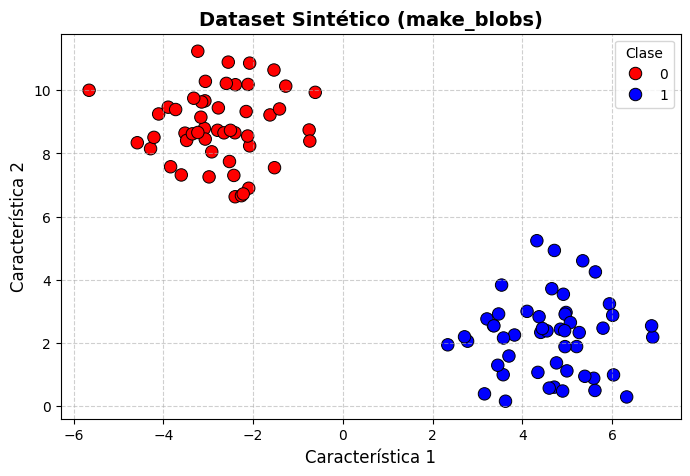

In [ ]:
# Configuramos el tamaño de la figura
plt.figure(figsize=(8, 5))

# Creamos un scatter plot coloreando por clase
sns.scatterplot(
    data=df,
    x='Caracteristica_1',
    y='Caracteristica_2',
    hue='Clase',
    palette=['red', 'blue'],
    s=80,
    edgecolor='k'
)

plt.title('Dataset Sintético (make_blobs)', fontsize=14, fontweight='bold')
plt.xlabel('Característica 1', fontsize=12)
plt.ylabel('Característica 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 4.3 Preprocesamiento de Datos
Dividiremos los datos en conjuntos de entrenamiento y prueba, y los estandarizaremos (las SVM son sensibles a la escala de los datos).

In [ ]:
# Importamos las herramientas de Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Dividimos los datos: 80% entrenamiento, 20% prueba, manteniendo la proporción de clases (stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Instanciamos el escalador
scaler = StandardScaler()

# Ajustamos con los datos de entrenamiento y transformamos
X_train_scaled = scaler.fit_transform(X_train)

# Transformamos los datos de prueba
X_test_scaled = scaler.transform(X_test)

print(f"Datos divididos y escalados. Muestras de entrenamiento: {X_train_scaled.shape[0]} | Muestras de prueba: {X_test_scaled.shape[0]}")

Datos divididos y escalados. Muestras de entrenamiento: 80 | Muestras de prueba: 20


### 4.4 Selección y Entrenamiento del Modelo (SVM)
Utilizaremos la clase `SVC` (Support Vector Classification) con un kernel lineal, ya que nuestros datos parecen linealmente separables.

In [ ]:
# Importamos el clasificador de Vectores de Soporte
from sklearn.svm import SVC

# Instanciamos el modelo usando un kernel lineal (búsqueda de una línea recta)
# C = Parámetro de regularización. Controla el equilibrio entre un margen amplio y clasificar correctamente los puntos de entrenamiento.
svm_model = SVC(kernel='linear', C=1.0, random_state=42)

# Entrenamos el modelo con los datos escalados
svm_model.fit(X_train_scaled, y_train)

print("Modelo SVM entrenado.")
print(f"Número de vectores de soporte encontrados: {len(svm_model.support_)}")

Modelo SVM entrenado.
Número de vectores de soporte encontrados: 3


### 4.5 Evaluación del Modelo (Métricas y Fronteras de Decisión)
Calcularemos la exactitud, la matriz de confusión y visualizaremos la frontera de decisión junto con el margen máximo.

Exactitud (Accuracy) en Prueba: 100.00%


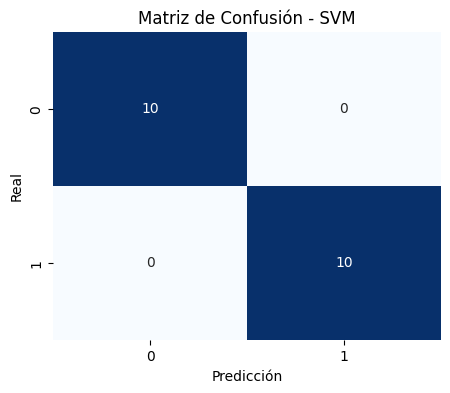

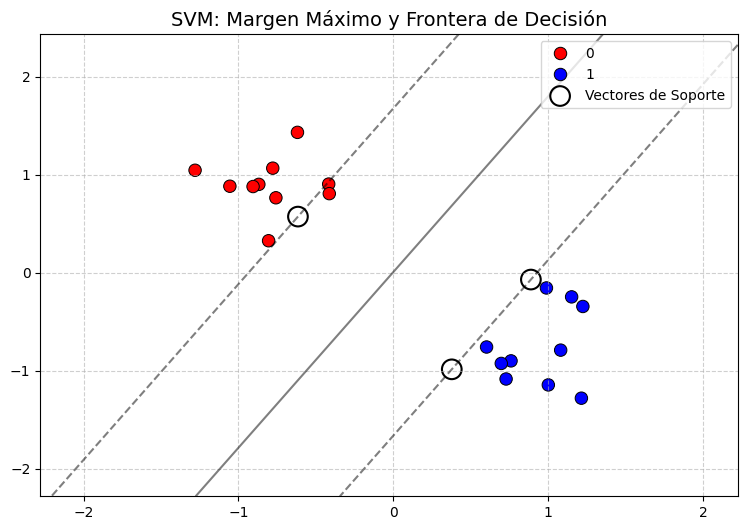

Las líneas punteadas muestran el 'margen'. La SVM maximizó la distancia entre estas líneas y los puntos más cercanos (círculos). Esto difiere del Perceptrón, que trazaría cualquier línea intermedia al azar.


In [ ]:
# Importamos métricas de evaluación
from sklearn.metrics import accuracy_score, confusion_matrix

# Hacemos predicciones sobre los datos de prueba
y_pred = svm_model.predict(X_test_scaled)

# Calculamos la exactitud (Accuracy)
accuracy = accuracy_score(y_test, y_pred)
print(f"Exactitud (Accuracy) en Prueba: {accuracy * 100:.2f}%")

# Calculamos la Matriz de Confusión
matriz_conf = confusion_matrix(y_test, y_pred)

# Visualizamos la matriz con un Heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusión - SVM')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

# VISUALIZACIÓN DEL MARGEN Y FRONTERA DE DECISIÓN

def plot_svm_boundary(model, X, y):
    # Creamos una malla (meshgrid) que cubra el rango de nuestros datos
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                         np.linspace(y_min, y_max, 500))

    # Calculamos la distancia a la frontera de decisión para cada punto de la malla
    # (decision_function nos da distancias continuas, no solo 0 o 1)
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(9, 6))

    # Dibujamos el Scatter Plot de los datos
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette=['red', 'blue'], s=80, edgecolor='k')

    # Dibujamos las líneas de la SVM usando contour
    # levels=[-1, 0, 1] dibujará los márgenes y el hiperplano central
    plt.contour(xx, yy, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
                linestyles=['--', '-', '--'])

    # Resaltamos los Vectores de Soporte con un círculo grande alrededor
    plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=200,
                linewidth=1.5, facecolors='none', edgecolors='k', label='Vectores de Soporte')

    plt.title('SVM: Margen Máximo y Frontera de Decisión', fontsize=14)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

# Llamamos a la función con el modelo y los datos de prueba escalados
plot_svm_boundary(svm_model, X_test_scaled, y_test)

print("Las líneas punteadas muestran el 'margen'. La SVM maximizó la distancia entre estas líneas y los puntos más cercanos (círculos). Esto difiere del Perceptrón, que trazaría cualquier línea intermedia al azar.")